**Generative AI Use**: For the purposes of the assignments, the use of generative AI is subject to the same policies regarding collaboration. Just as with other collaborators, each student must write down the solutions independently of the output of the interaction and the submission should include a note denoting the nature of the collaboration. The use of generative AI tools to substantially complete sections of the assignments is not in line with the spirit of the assignments, and would be a violation of the [Honor Code](https://communitystandards.stanford.edu/policies-and-guidance/honor-code).

# This mounts your Google Drive to the Colab VM.
from google.colab import drive
drive.mount('/content/drive')

# TODO: Enter the foldername in your Drive where you have saved the unzipped
# assignment folder, e.g. 'cs231n/assignments/assignment1/'
FOLDERNAME = 'cs231n/assignments/assignment1/'
assert FOLDERNAME is not None, "[!] Enter the foldername."

# Now that we've mounted your Drive, this ensures that
# the Python interpreter of the Colab VM can load
# python files from within it.
import sys
sys.path.append('/content/drive/My Drive/{}'.format(FOLDERNAME))

# This downloads the CIFAR-10 dataset to your Drive
# if it doesn't already exist.
%cd /content/drive/My\ Drive/$FOLDERNAME/cs231n/datasets/
!bash get_datasets.sh
%cd /content/drive/My\ Drive/$FOLDERNAME

# Image features exercise
*Complete and hand in this completed worksheet (including its outputs and any supporting code outside of the worksheet) with your assignment submission. For more details see the [assignments page](http://vision.stanford.edu/teaching/cs231n/assignments.html) on the course website.*

We have seen that we can achieve reasonable performance on an image classification task by training a linear classifier on the pixels of the input image. In this exercise we will show that we can improve our classification performance by training linear classifiers not on raw pixels but on features that are computed from the raw pixels.

All of your work for this exercise will be done in this notebook.

In [1]:
import random
import numpy as np
from cs231n.data_utils import load_CIFAR10
import matplotlib.pyplot as plt


%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# for auto-reloading extenrnal modules
# see http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
%load_ext autoreload
%autoreload 2

## Load data
Similar to previous exercises, we will load CIFAR-10 data from disk.

In [2]:
from cs231n.features import color_histogram_hsv, hog_feature

def get_CIFAR10_data(num_training=49000, num_validation=1000, num_test=1000):
    # Load the raw CIFAR-10 data
    cifar10_dir = 'cs231n/datasets/cifar-10-batches-py'

    # Cleaning up variables to prevent loading data multiple times (which may cause memory issue)
    try:
       del X_train, y_train
       del X_test, y_test
       print('Clear previously loaded data.')
    except:
       pass

    X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

    # Subsample the data
    mask = list(range(num_training, num_training + num_validation))
    X_val = X_train[mask]
    y_val = y_train[mask]
    mask = list(range(num_training))
    X_train = X_train[mask]
    y_train = y_train[mask]
    mask = list(range(num_test))
    X_test = X_test[mask]
    y_test = y_test[mask]

    return X_train, y_train, X_val, y_val, X_test, y_test

X_train, y_train, X_val, y_val, X_test, y_test = get_CIFAR10_data()

In [3]:
%pip install future

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: E:\python\python.exe -m pip install --upgrade pip


## Extract Features
For each image we will compute a Histogram of Oriented
Gradients (HOG) as well as a color histogram using the hue channel in HSV
color space. We form our final feature vector for each image by concatenating
the HOG and color histogram feature vectors.

Roughly speaking, HOG should capture the texture of the image while ignoring
color information, and the color histogram represents the color of the input
image while ignoring texture. As a result, we expect that using both together
ought to work better than using either alone. Verifying this assumption would
be a good thing to try for your own interest.

The `hog_feature` and `color_histogram_hsv` functions both operate on a single
image and return a feature vector for that image. The extract_features
function takes a set of images and a list of feature functions and evaluates
each feature function on each image, storing the results in a matrix where
each column is the concatenation of all feature vectors for a single image.

In [4]:
from cs231n.features import *

# num_color_bins = 10 # Number of bins in the color histogram
num_color_bins = 25 # Number of bins in the color histogram
feature_fns = [hog_feature, lambda img: color_histogram_hsv(img, nbin=num_color_bins)]
X_train_feats = extract_features(X_train, feature_fns, verbose=True)
X_val_feats = extract_features(X_val, feature_fns)
X_test_feats = extract_features(X_test, feature_fns)

# Preprocessing: Subtract the mean feature
mean_feat = np.mean(X_train_feats, axis=0, keepdims=True)
X_train_feats -= mean_feat
X_val_feats -= mean_feat
X_test_feats -= mean_feat

# Preprocessing: Divide by standard deviation. This ensures that each feature
# has roughly the same scale.
std_feat = np.std(X_train_feats, axis=0, keepdims=True)
X_train_feats /= std_feat
X_val_feats /= std_feat
X_test_feats /= std_feat

# Preprocessing: Add a bias dimension
X_train_feats = np.hstack([X_train_feats, np.ones((X_train_feats.shape[0], 1))])
X_val_feats = np.hstack([X_val_feats, np.ones((X_val_feats.shape[0], 1))])
X_test_feats = np.hstack([X_test_feats, np.ones((X_test_feats.shape[0], 1))])

Done extracting features for 1000 / 49000 images
Done extracting features for 2000 / 49000 images
Done extracting features for 3000 / 49000 images
Done extracting features for 4000 / 49000 images
Done extracting features for 5000 / 49000 images
Done extracting features for 6000 / 49000 images
Done extracting features for 7000 / 49000 images
Done extracting features for 8000 / 49000 images
Done extracting features for 9000 / 49000 images
Done extracting features for 10000 / 49000 images
Done extracting features for 11000 / 49000 images
Done extracting features for 12000 / 49000 images
Done extracting features for 13000 / 49000 images
Done extracting features for 14000 / 49000 images
Done extracting features for 15000 / 49000 images
Done extracting features for 16000 / 49000 images
Done extracting features for 17000 / 49000 images
Done extracting features for 18000 / 49000 images
Done extracting features for 19000 / 49000 images
Done extracting features for 20000 / 49000 images
Done extr

## Train Softmax classifier on features
Using the Softmax code developed earlier in the assignment, train Softmax classifiers on top of the features extracted above; this should achieve better results than training them directly on top of raw pixels.

In [5]:
import numpy as np
from cs231n.classifiers.linear_classifier import Softmax

# 调整学习率和正则化强度的范围
learning_rates = [1e-3, 2e-2, 3e-2]
regularization_strengths = [1e-4, 5e-4, 1e-3]

results = {}
best_val = -1
best_softmax = None

for lr in learning_rates:
    for reg in regularization_strengths:

        # Initialize Softmax classifier
        softmax = Softmax()

        # Train on extracted features
        softmax.train(
            X_train_feats,
            y_train,
            learning_rate=lr,
            reg=reg,
            num_iters=2500,
            verbose=False
        )

        # Training accuracy
        y_train_pred = softmax.predict(X_train_feats)
        train_accuracy = np.mean(y_train_pred == y_train)

        # Validation accuracy
        y_val_pred = softmax.predict(X_val_feats)
        val_accuracy = np.mean(y_val_pred == y_val)

        # Save results
        results[(lr, reg)] = (train_accuracy, val_accuracy)

        # Update best classifier
        if val_accuracy > best_val:
            best_val = val_accuracy
            best_softmax = softmax

# Print out results.
for lr, reg in sorted(results):
    train_accuracy, val_accuracy = results[(lr, reg)]
    print('lr %e reg %e train accuracy: %f val accuracy: %f' % (
        lr, reg, train_accuracy, val_accuracy))

print('best validation accuracy achieved: %f' % best_val)

lr 1.000000e-03 reg 1.000000e-04 train accuracy: 0.465592 val accuracy: 0.473000
lr 1.000000e-03 reg 5.000000e-04 train accuracy: 0.465796 val accuracy: 0.477000
lr 1.000000e-03 reg 1.000000e-03 train accuracy: 0.465184 val accuracy: 0.472000
lr 2.000000e-02 reg 1.000000e-04 train accuracy: 0.525755 val accuracy: 0.521000
lr 2.000000e-02 reg 5.000000e-04 train accuracy: 0.524000 val accuracy: 0.522000
lr 2.000000e-02 reg 1.000000e-03 train accuracy: 0.525653 val accuracy: 0.528000
lr 3.000000e-02 reg 1.000000e-04 train accuracy: 0.526265 val accuracy: 0.526000
lr 3.000000e-02 reg 5.000000e-04 train accuracy: 0.524694 val accuracy: 0.520000
lr 3.000000e-02 reg 1.000000e-03 train accuracy: 0.526633 val accuracy: 0.530000
best validation accuracy achieved: 0.530000


In [6]:
# Evaluate your trained Softmax on the test set: you should be able to get at least 0.42
y_test_pred = best_softmax.predict(X_test_feats)
test_accuracy = np.mean(y_test == y_test_pred)
print(test_accuracy)

0.516


In [7]:
# Save best softmax model
best_softmax.save("best_softmax_features.npy")

best_softmax_features.npy saved.


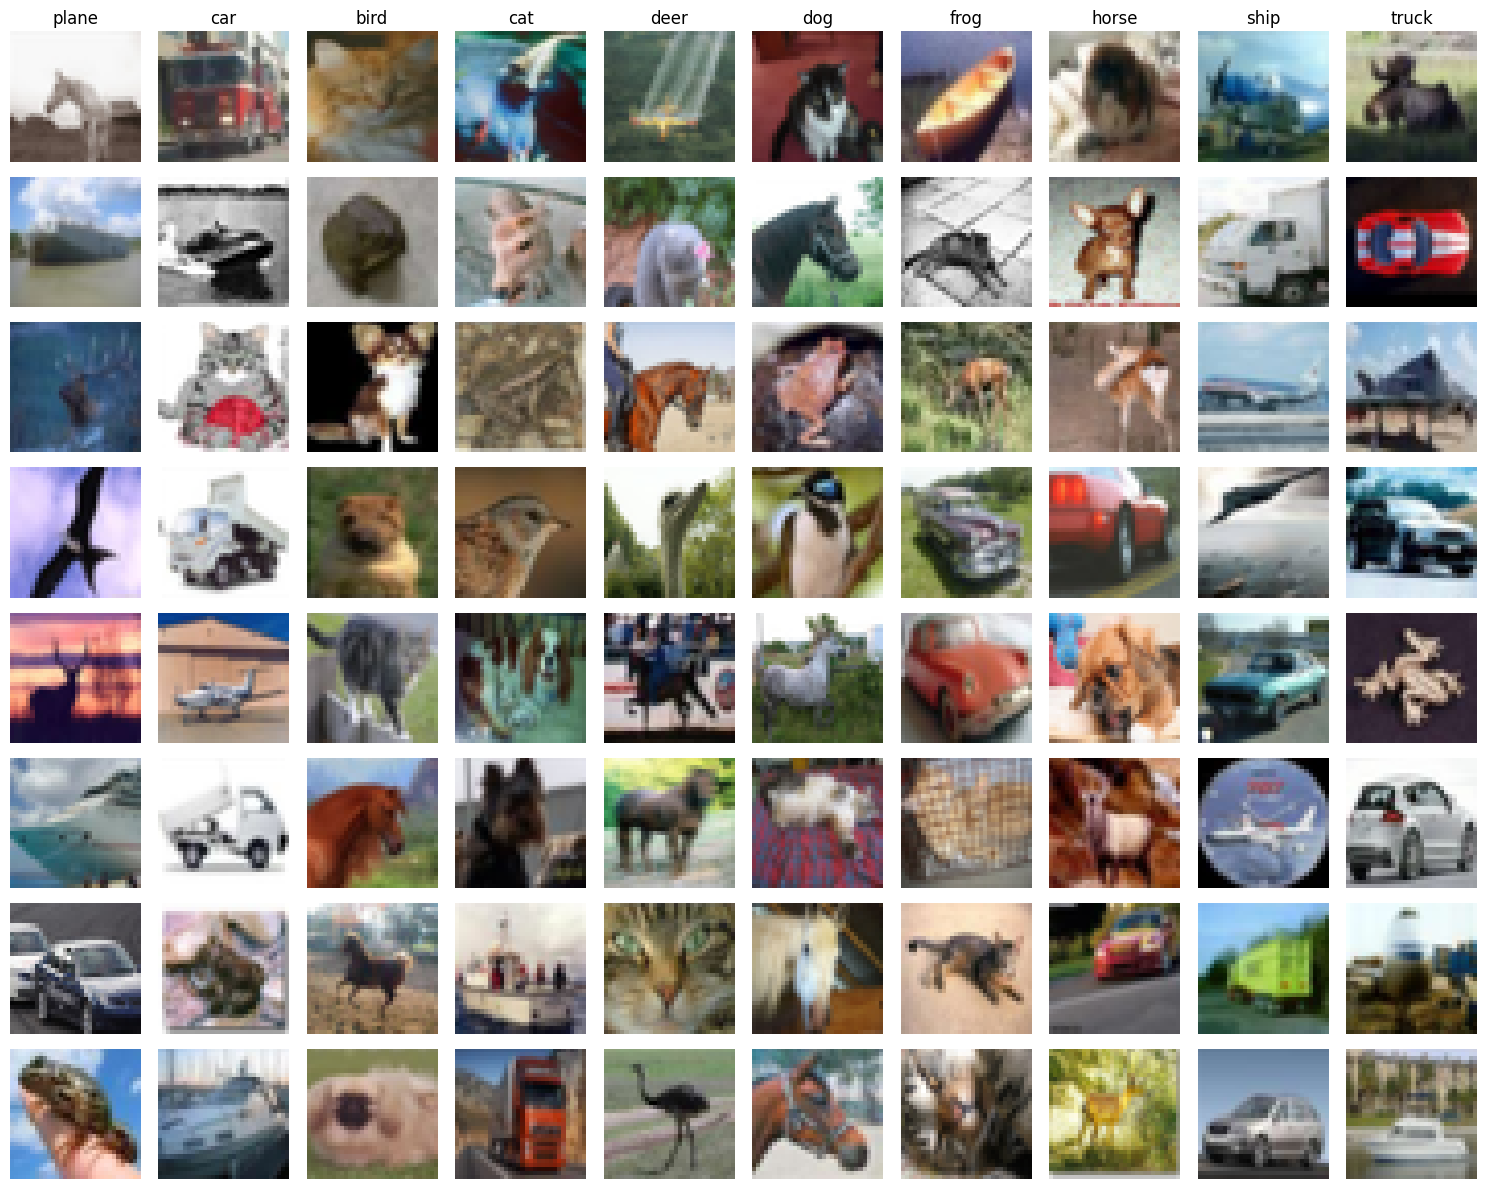

In [8]:
examples_per_class = 8

classes = ['plane', 'car', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(15, 12))

for cls, cls_name in enumerate(classes):

    idxs = np.where((y_test != cls) & (y_test_pred == cls))[0]

    # 检查当前类别是否有错误分类的图片
    if len(idxs) == 0:
        print(f"{cls_name}: 没有找到错误分类的图片")
        continue

    # 如果不足8张，就选择实际存在的数量
    num_samples = min(len(idxs), examples_per_class)

    idxs = np.random.choice(idxs, num_samples, replace=False)

    for i, idx in enumerate(idxs):

        plt.subplot(examples_per_class, len(classes),
                    i * len(classes) + cls + 1)

        plt.imshow(X_test[idx].astype('uint8'))
        plt.axis('off')

        if i == 0:
            plt.title(cls_name)

plt.tight_layout()
plt.show()

### Inline question 1:
Describe the misclassification results that you see. Do they make sense?


$\color{blue}{\textit Your Answer:}$
这些错误分类结果总体上是合理的。
模型容易混淆具有相似视觉特征的类别，例如猫和狗、汽车和卡车。
有些图片由于分辨率较低、背景复杂，或者颜色和形状相似，因此很难正确分类。
由于 CIFAR-10 数据集中的图片尺寸只有 32×32 像素，模型有时难以区分不同的物体。
因此，这些错误分类是可以理解的。




## Neural Network on image features
Earlier in this assigment we saw that training a two-layer neural network on raw pixels achieved better classification performance than linear classifiers on raw pixels. In this notebook we have seen that linear classifiers on image features outperform linear classifiers on raw pixels.

For completeness, we should also try training a neural network on image features. This approach should outperform all previous approaches: you should easily be able to achieve over 55% classification accuracy on the test set; our best model achieves about 60% classification accuracy.

In [9]:
# Preprocessing: Remove the bias dimension
# Make sure to run this cell only ONCE
print(X_train_feats.shape)
X_train_feats = X_train_feats[:, :-1]
X_val_feats = X_val_feats[:, :-1]
X_test_feats = X_test_feats[:, :-1]

print(X_train_feats.shape)

(49000, 170)
(49000, 169)


In [10]:
from cs231n.classifiers.fc_net import TwoLayerNet
from cs231n.solver import Solver

input_dim = X_train_feats.shape[1]
hidden_dim = 500
num_classes = 10

data = {
    'X_train': X_train_feats,
    'y_train': y_train,
    'X_val': X_val_feats,
    'y_val': y_val,
    'X_test': X_test_feats,
    'y_test': y_test,
}

net = TwoLayerNet(input_dim, hidden_dim, num_classes)
best_net = None

################################################################################
# TODO: Train a two-layer neural network on image features. You may want to    #
# cross-validate various parameters as in previous sections. Store your best   #
# model in the best_net variable.                                              #
################################################################################
best_val_acc = -1

# 1. 定义超参数搜索空间
# 学习率和正则化强度通常采用对数尺度进行搜索
learning_rates = [5e-4, 1e-3, 2e-3, 3e-3]
regularization_strengths = [1e-4, 1e-3, 1e-2, 1e-1]

# 2. 循环遍历所有超参数组合
for lr in learning_rates:
    for reg in regularization_strengths:
        
        # 实例化一个新的两层神经网络模型
        model = TwoLayerNet(input_dim, hidden_dim, num_classes, 
                            weight_scale=1e-3, reg=reg)
        
        # 实例化 Solver
        # 推荐使用 adam 优化器，因为它在特征上收敛得更好、更快
        solver = Solver(model, data,
                        update_rule='adam',
                        optim_config={
                          'learning_rate': lr,
                        },
                        lr_decay=0.95,      # 学习率衰减
                        num_epochs=15,      # 训练轮数
                        batch_size=200,
                        print_every=100,
                        verbose=False)      # 设为False防止输出刷屏
        
        # 开始训练模型
        solver.train()
        
        # 获取模型在验证集上的最高准确率
        val_acc = solver.best_val_acc
        
        # 打印当前参数的表现
        print(f"lr: {lr:.1e}, reg: {reg:.1e}, val accuracy: {val_acc:.4f}")
        
        # 3. 如果当前模型表现更好，则更新 best_net
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            # 因为 Solver 训练结束后会自动把模型参数恢复为验证集最好的那一轮
            # 所以直接将 model 赋值给 best_net 即可
            best_net = model

print(f'\nBest validation accuracy achieved: {best_val_acc:.4f}')

lr: 5.0e-04, reg: 1.0e-04, val accuracy: 0.6180
lr: 5.0e-04, reg: 1.0e-03, val accuracy: 0.6140
lr: 5.0e-04, reg: 1.0e-02, val accuracy: 0.5680
lr: 5.0e-04, reg: 1.0e-01, val accuracy: 0.4530
lr: 1.0e-03, reg: 1.0e-04, val accuracy: 0.6030
lr: 1.0e-03, reg: 1.0e-03, val accuracy: 0.6080
lr: 1.0e-03, reg: 1.0e-02, val accuracy: 0.5780
lr: 1.0e-03, reg: 1.0e-01, val accuracy: 0.4480
lr: 2.0e-03, reg: 1.0e-04, val accuracy: 0.6020
lr: 2.0e-03, reg: 1.0e-03, val accuracy: 0.6120
lr: 2.0e-03, reg: 1.0e-02, val accuracy: 0.5730
lr: 2.0e-03, reg: 1.0e-01, val accuracy: 0.4450
lr: 3.0e-03, reg: 1.0e-04, val accuracy: 0.5900
lr: 3.0e-03, reg: 1.0e-03, val accuracy: 0.6120
lr: 3.0e-03, reg: 1.0e-02, val accuracy: 0.5630
lr: 3.0e-03, reg: 1.0e-01, val accuracy: 0.4510

Best validation accuracy achieved: 0.6180


In [11]:
# Run your best neural net classifier on the test set. You should be able
# to get more than 58% accuracy. It is also possible to get >60% accuracy
# with careful tuning.

y_test_pred = np.argmax(best_net.loss(data['X_test']), axis=1)
test_acc = (y_test_pred == data['y_test']).mean()
print(test_acc)

0.585


In [12]:
# Save best model
best_net.save("best_two_layer_net_features.npy")

best_two_layer_net_features.npy saved.
